# S08: why is |s| > 3 routine? A diagnostic of the S05 s-score (no trading)

Pre-registration: [`S08_README.md`](S08_README.md). Engine: `src/equity_trading/s08.py`.

| Variant | s-score |
|---|---|
| V0 | S05 as traded |
| V1 | overnight bar excluded from the residual (window fit and live) |
| V2 | V1 scaled by a HAR-style volatility ratio (1-, 5-, 20-session realized variance) |
| V3 | V0 scaled by the same volatility ratio |

Two targets (amendment A1): **hedged** = forward β-hedged return r − β·r_ETF (no α), what a position earns, used for every reading; **residual** = forward S05 residual increments (r − α − β·r_ETF), the original target, reported for comparison. Both include overnight bars.

In [1]:
SAMPLE_EVERY = 4             # bars between sampled cross-sections for IC and bucket tables
HORIZONS = {"1h": 4, "1d": 26, "5d": 130}
ROUND_TRIP_BPS = 13.0        # S05b measured cost per trade (stock + hedge, market orders)

import json, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, s04, s05, s08
from equity_trading.alpaca import ALPACA_VERSION, download_years

SYNTHETIC = os.environ.get("S08_SYNTHETIC") == "1"
YEARS = list(range(2020, 2026))                      # 2026 not used
CFG = s08.S08Config()
OUT = ROOT / "results" / ("s08_synthetic" if SYNTHETIC else "s08")
OUT.mkdir(parents=True, exist_ok=True)
VARS = ["s0", "s1", "s2", "s3"]
NAMES = {"s0": "V0 S05", "s1": "V1 no overnight", "s2": "V2 no overnight + vol", "s3": "V3 S05 + vol"}
COL = {"s0": "#8a8a84", "s1": "#2a78d6", "s2": "#1baf7a", "s3": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
    BENCH, YEARS, MIN_N = "XLK", [2024, 2025], 20
else:
    constituents = pd.read_csv(ROOT / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
    BENCH, MIN_N = "SPY", 50
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | stocks={len(STOCKS)} | {CFG}")

synthetic=False | stocks=503 | S08Config(window_sessions=20, min_bar_share=0.95, max_tau_frac=0.5, rv_short_sessions=1, rv_mid_sessions=5, lambda_clip=(0.25, 4.0), kurt_sample_per_day=5, seed=42)


## 1. Data and s-score paths

In [2]:
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
else:
    download_years(STOCKS + ETFS + [BENCH], "15Min", YEARS, workers=8)
    panel = s04.cached_panel(STOCKS + ETFS + [BENCH], "15Min", YEARS, ffill_bars=2)
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
R = s08.compute(panel, SC, EC, CFG)
days = pd.to_datetime(panel.days)
first_live = panel.day_start[CFG.window_sessions]
ROWS = np.arange(first_live, len(panel.index) - max(HORIZONS.values()) - 1, SAMPLE_EVERY)
FWD_RES = {h: s08.forward_sum(R["eps"], n) for h, n in HORIZONS.items()}
FWD = {h: s08.forward_sum(R["hedged"], n) for h, n in HORIZONS.items()}     # primary (A1): tradable hedged return
print(f"panel {panel.c.shape}, stocks {len(TRADED)}, computed in {(time.time() - t0) / 60:.1f} min; sampled cross-sections {len(ROWS):,}")

15Min: 0 batches to download (0 symbol-years), 8 parallel requests
  day 21/1508


D:\Projects\equity_trading\src\equity_trading\s08.py:116: RuntimeWarning: Mean of empty slice
  rv20 = np.nanmean(np.where(intr, eds, np.nan) ** 2, axis=0)


  day 271/1508
  day 521/1508
  day 771/1508
  day 1021/1508
  day 1271/1508
panel (39064, 513), stocks 501, computed in 1.6 min; sampled cross-sections 9,604


## 2. How extreme is s? Exceedance vs a normal OU, and by time of day

,>1.25,>2,>3,>4
V0 S05,0.3179,0.1128,0.0292,0.0106
V1 no overnight,0.5628,0.3517,0.1601,0.0618
V2 no overnight + vol,0.5665,0.3577,0.1684,0.0697
V3 S05 + vol,0.3274,0.1138,0.0236,0.0060
normal OU,0.2113,0.0455,0.0027,0.0001


C:\Users\Iván\AppData\Local\Temp\ipykernel_12664\260309936.py:5: RuntimeWarning: Mean of empty slice
  by_slot = pd.DataFrame({NAMES[v]: pd.Series(np.nanmean(np.where(np.isfinite(R[v]), np.abs(R[v]) > 3, np.nan), axis=1)).groupby(slot).mean()


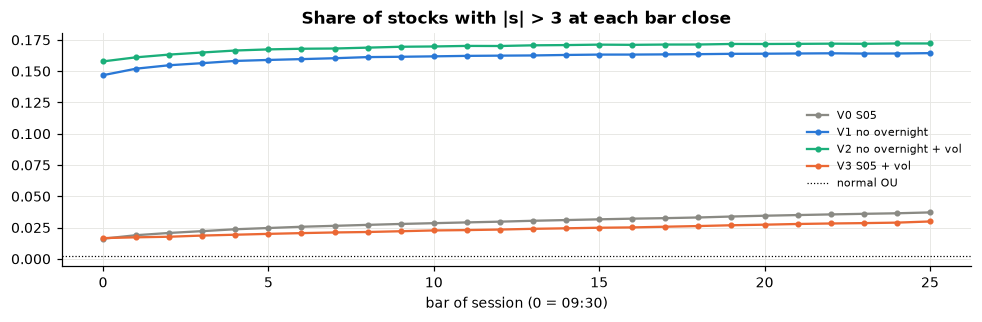

In [3]:
exc = pd.DataFrame({NAMES[v]: s08.exceedance(R[v]) for v in VARS})
exc["normal OU"] = pd.Series(s08.normal_exceedance())
display(exc.T.round(4))
slot = R["slot"]
by_slot = pd.DataFrame({NAMES[v]: pd.Series(np.nanmean(np.where(np.isfinite(R[v]), np.abs(R[v]) > 3, np.nan), axis=1)).groupby(slot).mean()
                        for v in VARS})
fig, ax = plt.subplots(figsize=(9, 3))
for v in VARS:
    ax.plot(by_slot.index, by_slot[NAMES[v]], marker="o", ms=3, color=COL[v], label=NAMES[v])
ax.axhline(0.0027, color="k", lw=0.8, ls=":", label="normal OU")
ax.set_xlabel("bar of session (0 = 09:30)"); ax.set_title("Share of stocks with |s| > 3 at each bar close"); ax.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## 3. Is it the mean? Share of the extreme V0 scores explained by −m/σ

In [4]:
ms = np.abs(R["m_over_sig0"])
big = np.abs(R["s0"]) > 3
decomp = {"share |m/sigma| > 1": float(np.nanmean(ms > 1)), "share |m/sigma| > 2": float(np.nanmean(ms > 2)),
          "share |m/sigma| > 3": float(np.nanmean(ms > 3)),
          "among |s0| > 3: share with |m/sigma| > 2": float(np.nanmean((ms > 2)[big])),
          "among |s0| > 3: share where sign(-m) = sign(s)": float(np.nanmean((np.sign(R["m_over_sig0"]) == np.sign(R["s0"]))[big]))}
display(pd.Series(decomp).round(4).to_frame("V0"))

,V0
share |m/sigma| > 1,0.2612
share |m/sigma| > 2,0.0198
share |m/sigma| > 3,0.0004
among |s0| > 3: share with |m/sigma| > 2,0.1782
among |s0| > 3: share where sign(-m) = sign(s),0.8490


## 4. Tails of the OU innovations (is a Student-t warranted?)

In [5]:
from scipy import stats
kurt = {"V0 (with overnight) median excess kurtosis": float(np.nanmedian(R["kurt0"])),
        "V1 (no overnight) median excess kurtosis": float(np.nanmedian(R["kurt1"]))}
rng = np.random.default_rng(0)
zs = [z for _, _, z in R["z_samples"]]
pick = rng.choice(len(zs), size=min(800, len(zs)), replace=False)
nus = []
for k in pick:
    z = zs[k][np.isfinite(zs[k])]
    try:
        nu, _, _ = stats.t.fit(z, floc=0.0)
        nus.append(min(nu, 200.0))
    except Exception:
        pass
kurt.update({"V1 innovations: Student-t nu, median (sample)": float(np.median(nus)),
             "V1 innovations: share of stock-days with nu < 5": float(np.mean(np.array(nus) < 5))})
display(pd.Series(kurt).round(3).to_frame())

,0
V0 (with overnight) median excess kurtosis,9.770
V1 (no overnight) median excess kurtosis,3.022
"V1 innovations: Student-t nu, median (sample)",3.958
V1 innovations: share of stock-days with nu < 5,0.806


## 5. Signal quality: rank IC of −s against forward residual return

In [6]:
ic_rows, ic_series = [], {}
for v in VARS:
    for h in HORIZONS:
        ic = s08.rank_ic(-R[v], FWD[h], ROWS, min_n=MIN_N)
        d = pd.Series(ic, index=days[np.searchsorted(panel.day_start, ROWS, side="right") - 1]).groupby(level=0).mean().dropna()
        ic_series[(v, h)] = d
        lag = {"1h": 1, "1d": 1, "5d": 5}[h]
        import statsmodels.api as sm
        nw = sm.OLS(d.to_numpy(), np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lag})
        ic_rows.append({"variant": NAMES[v], "horizon": h, "mean_IC": float(d.mean()), "t_NW": float(nw.tvalues[0]),
                        "share_days_IC>0": float((d > 0).mean())})
ic_tab = pd.DataFrame(ic_rows).pivot(index="variant", columns="horizon")
print("Target: hedged return (primary)"); display(ic_tab.round(4))
ic_res = pd.DataFrame({NAMES[v]: {h: float(np.nanmean(s08.rank_ic(-R[v], FWD_RES[h], ROWS, min_n=MIN_N))) for h in HORIZONS} for v in VARS}).T
print("Target: residual incl. -alpha (original, for comparison)"); display(ic_res.round(4))
ic_year = pd.DataFrame({NAMES[v]: ic_series[(v, "1d")].groupby(ic_series[(v, "1d")].index.year).mean() for v in VARS})
display(ic_year.round(4).rename_axis("mean IC, 1d horizon"))

Target: hedged return (primary)


mean_IC                    t_NW                  \
horizon                    1d      1h      5d      1d      1h      5d   
variant                                                                 
V0 S05                 0.0135  0.0084  0.0145  4.0536  6.4160  2.6761   
V1 no overnight        0.0054  0.0030  0.0063  1.8027  2.5447  1.3142   
V2 no overnight + vol  0.0053  0.0028  0.0062  1.7502  2.4672  1.2898   
V3 S05 + vol           0.0133  0.0084  0.0142  3.9893  6.4185  2.6110   

                      share_days_IC>0                  
horizon                            1d      1h      5d  
variant                                                
V0 S05                         0.5482  0.5947  0.5381  
V1 no overnight                0.5226  0.5394  0.5158  
V2 no overnight + vol          0.5219  0.5462  0.5158  
V3 S05 + vol                   0.5482  0.5968  0.5354

Target: residual incl. -alpha (original, for comparison)


,1h,1d,5d
V0 S05,0.0031,0.0206,0.1016
V1 no overnight,0.0487,0.1005,0.2240
V2 no overnight + vol,0.0485,0.0998,0.2223
V3 S05 + vol,0.0021,0.0185,0.0978


,V0 S05,V1 no overnight,V2 no overnight + vol,V3 S05 + vol
"mean IC, 1d horizon",,,,
2020,0.0123,0.0103,0.0102,0.0123
2021,0.0110,0.0036,0.0032,0.0106
2022,0.0102,0.0067,0.0068,0.0103
2023,0.0133,0.0035,0.0033,0.0129
2024,0.0192,0.0048,0.0046,0.0188
2025,0.0149,0.0042,0.0038,0.0145


## 6. Expected contrarian residual return by s bucket (bps), against the S05b round trip

Contrarian hedged return, bps (primary)


V0 S05            V1 no overnight        V2 no overnight + vol  \
                  1d         5d              1d     5d                    1d   
bucket                                                                         
(-inf, -4.0]    6.35  29.559999            2.64  12.47                  1.20   
(-4.0, -3.0]    2.82  14.810000            1.25   4.11                  1.76   
(-3.0, -2.0]    1.46   9.860000            1.31   2.69                  1.66   
(-2.0, -1.25]   1.02   4.770000            0.87   2.19                  0.43   
(-1.25, -0.5]   0.88   3.880000           -0.04   2.43                  0.40   
(-0.5, 0.5]    -0.03   1.200000            0.53   1.37                  0.38   
(0.5, 1.25]     0.27   4.090000            1.19   4.41                  1.64   
(1.25, 2.0]     1.91   8.550000            1.96   3.65                  2.02   
(2.0, 3.0]      3.12  11.820000            1.54   3.35                  1.54   
(3.0, 4.0]      4.86  19.070000            0.12   2.32                 -0.30   
(4.0, inf]      5.05  17.799999            1.46   6.13                  0.22   

                    V3 S05 + vol         
                 5d           1d     5d  
bucket                                   
(-inf, -4.0]   6.41         2.33  12.15  
(-4.0, -3.0]   4.04         3.96  11.95  
(-3.0, -2.0]   2.95         2.54   8.68  
(-2.0, -1.25]  3.10         0.94   5.88  
(-1.25, -0.5]  2.81         0.75   4.12  
(-0.5, 0.5]    1.55        -0.11   1.51  
(0.5, 1.25]    5.02         0.74   4.40  
(1.25, 2.0]    4.71         1.90   7.99  
(2.0, 3.0]     4.26         2.06  11.80  
(3.0, 4.0]    -1.39         1.31  11.05  
(4.0, inf]     2.39         6.17   4.04

Contrarian residual return incl. -alpha, bps (original)


V0 S05             V1 no overnight              \
                      1d          5d              1d          5d   
bucket                                                             
(-inf, -4.0]   23.790001  178.160004       31.500000  172.330002   
(-4.0, -3.0]   10.530000   93.150002       22.709999  121.000000   
(-3.0, -2.0]    5.160000   63.750000       16.990000   86.519997   
(-2.0, -1.25]   2.940000   42.709999       11.680000   58.389999   
(-1.25, -0.5]   1.950000   25.100000        5.880000   31.959999   
(-0.5, 0.5]     0.210000    7.170000        2.080000    9.170000   
(0.5, 1.25]     0.920000   24.129999        6.410000   31.280001   
(1.25, 2.0]     3.870000   47.570000       12.270000   57.990002   
(2.0, 3.0]      6.970000   67.440002       17.170000   87.849998   
(3.0, 4.0]     11.320000   92.199997       22.150000  123.809998   
(4.0, inf]     20.340000  155.000000       30.500000  167.789993   

              V2 no overnight + vol             V3 S05 + vol              
                                 1d          5d           1d          5d  
bucket                                                                    
(-inf, -4.0]              26.680000  147.889999    13.920000  145.949997  
(-4.0, -3.0]              21.740000  113.489998     6.040000   66.790001  
(-3.0, -2.0]              17.049999   85.160004     3.010000   49.580002  
(-2.0, -1.25]             11.470000   60.439999     2.340000   41.299999  
(-1.25, -0.5]              7.060000   36.009998     2.920000   29.709999  
(-0.5, 0.5]                2.070000   10.000000     0.570000    9.170000  
(0.5, 1.25]                7.100000   33.130001     2.280000   27.600000  
(1.25, 2.0]               12.580000   60.209999     3.480000   45.410000  
(2.0, 3.0]                17.260000   88.900002     3.220000   57.639999  
(3.0, 4.0]                20.600000  114.220001     4.630000   74.459999  
(4.0, inf]                26.610001  150.190002    18.049999  134.919998

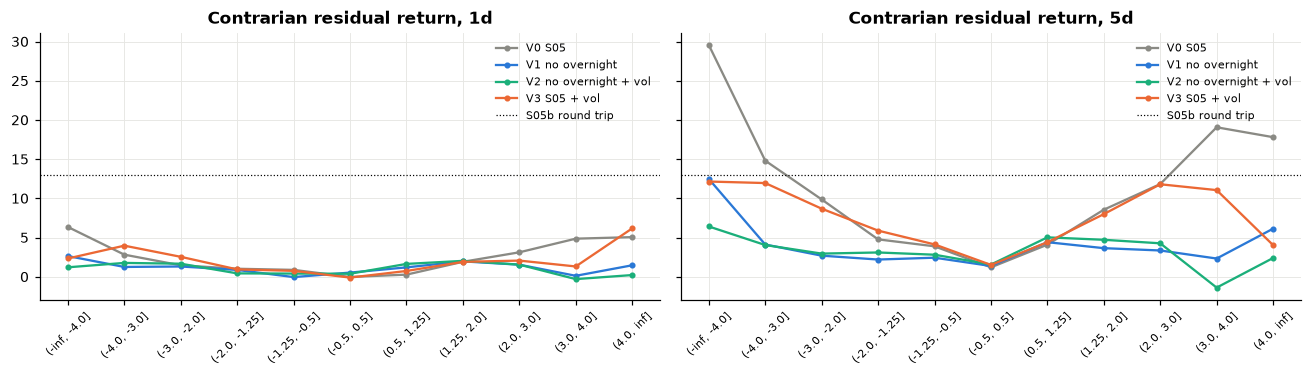

In [7]:
bk = {}
for v in VARS:
    for h in ("1d", "5d"):
        bk[(NAMES[v], h)] = s08.bucket_returns(R[v], FWD[h], ROWS)["contrarian_bps"]
bucket_tab = pd.DataFrame(bk)
print("Contrarian hedged return, bps (primary)"); display(bucket_tab.round(2))
bucket_res = pd.DataFrame({(NAMES[v], h): s08.bucket_returns(R[v], FWD_RES[h], ROWS)["contrarian_bps"] for v in VARS for h in ("1d", "5d")})
print("Contrarian residual return incl. -alpha, bps (original)"); display(bucket_res.round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for i, h in enumerate(("1d", "5d")):
    for v in VARS:
        y = bucket_tab[(NAMES[v], h)]
        ax[i].plot(range(len(y)), y.values, marker="o", ms=3, color=COL[v], label=NAMES[v])
    ax[i].axhline(ROUND_TRIP_BPS, color="k", ls=":", lw=0.8, label="S05b round trip")
    ax[i].set_xticks(range(len(y))); ax[i].set_xticklabels([str(b) for b in y.index], rotation=45, fontsize=7)
    ax[i].set_title(f"Contrarian residual return, {h}"); ax[i].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## 7. Calibration within the session: P(s reaches 0 before |s| = 4) vs OU

In [8]:
cal = {}
sub = ROWS[::5]
for v in ("s0", "s1", "s2", "s3"):
    hd = s08.within_day_hits(R[v], panel.day_start, sub)
    hd["bucket"] = pd.cut(hd.abs_s0, [1.25, 1.5, 2, 3, 4], include_lowest=True)
    g = hd.groupby("bucket", observed=True)
    cal[NAMES[v]] = pd.DataFrame({"n": g.size(), "resolved_share": g.hit_zero.apply(lambda x: x.notna().mean()),
                                  "P_zero_first": g.hit_zero.mean(),
                                  "OU": g.abs_s0.apply(lambda x: s08.ou_hit_zero_prob(x).mean())})
display(pd.concat(cal).round(3))

n  resolved_share  P_zero_first  \
                      bucket                                               
V0 S05                (1.249, 1.5]   69878           0.018         0.904   
                      (1.5, 2.0]     90929           0.013         0.715   
                      (2.0, 3.0]     65135           0.028         0.172   
                      (3.0, 4.0]     14311           0.259         0.010   
V1 no overnight       (1.249, 1.5]   59933           0.028         0.913   
                      (1.5, 2.0]    105485           0.016         0.738   
                      (2.0, 3.0]    150234           0.022         0.195   
                      (3.0, 4.0]     77002           0.202         0.005   
V2 no overnight + vol (1.249, 1.5]   59303           0.024         0.965   
                      (1.5, 2.0]    104367           0.013         0.865   
                      (2.0, 3.0]    148103           0.017         0.202   
                      (3.0, 4.0]     77498           0.222         0.003   
V3 S05 + vol          (1.249, 1.5]   71922           0.016         0.967   
                      (1.5, 2.0]     95260           0.009         0.858   
                      (2.0, 3.0]     70297           0.016         0.227   
                      (3.0, 4.0]     13597           0.205         0.008   

                                       OU  
                      bucket               
V0 S05                (1.249, 1.5]  0.998  
                      (1.5, 2.0]    0.996  
                      (2.0, 3.0]    0.986  
                      (3.0, 4.0]    0.800  
V1 no overnight       (1.249, 1.5]  0.998  
                      (1.5, 2.0]    0.996  
                      (2.0, 3.0]    0.984  
                      (3.0, 4.0]    0.768  
V2 no overnight + vol (1.249, 1.5]  0.998  
                      (1.5, 2.0]    0.996  
                      (2.0, 3.0]    0.984  
                      (3.0, 4.0]    0.766  
V3 S05 + vol          (1.249, 1.5]  0.998  
                      (1.5, 2.0]    0.996  
                      (2.0, 3.0]    0.987  
                      (3.0, 4.0]    0.812

## 8. Regimes: does mean reversion depend on the market volatility state?

In [9]:
br = np.log(panel.c[:, panel.symbols.index(BENCH)])
r_b = np.diff(br, prepend=np.nan)
r_b[panel.day_start[:-1]] = np.nan                    # intraday only
rv_day = pd.Series([np.nansum(r_b[a:b] ** 2) for a, b in zip(panel.day_start[:-1], panel.day_start[1:])], index=days)
rv20 = rv_day.rolling(20).mean().shift(1)             # known before the day starts
terc = pd.qcut(rv20, 3, labels=["low vol", "mid vol", "high vol"])
reg = {}
for lab in ["low vol", "mid vol", "high vol"]:
    dd = terc.index[terc == lab]
    di = np.isin(days, dd)
    tau = R["tau0"][di]
    rec = {"days": int(di.sum()), "median_tau_sessions": float(np.nanmedian(tau) / 26)}
    for v in ("s0", "s1", "s3"):
        s_ = ic_series[(v, "1d")]
        rec[f"IC_1d {NAMES[v]}"] = float(s_[s_.index.isin(dd)].mean())
    row_days = days[np.searchsorted(panel.day_start, ROWS, side="right") - 1]
    rr = ROWS[np.isin(row_days, dd)]
    for v in ("s0", "s1"):
        b = s08.bucket_returns(R[v], FWD["5d"], rr)["contrarian_bps"]
        rec[f"{NAMES[v]} contrarian bps, |s| 2-3, 5d"] = float(b[[i for i in b.index if i.left in (-3.0, 2.0)]].mean())
    reg[lab] = rec
reg_tab = pd.DataFrame(reg).T
display(reg_tab.round(3))

,days,median_tau_sessions,IC_1d V0 S05,IC_1d V1 no overnight,IC_1d V3 S05 + vol,"V0 S05 contrarian bps, |s| 2-3, 5d","V1 no overnight contrarian bps, |s| 2-3, 5d"
low vol,496.0,2.532,0.017,0.006,0.017,7.437,1.296
mid vol,496.0,2.529,0.010,0.001,0.009,-1.034,-3.737
high vol,496.0,2.440,0.014,0.009,0.013,25.844,11.658


## 9. Pre-stated readings and summary

In [10]:
def ic(v, h): return float(ic_tab.loc[NAMES[v], ("mean_IC", h)])
best_bps_5d = float(bucket_tab.xs("5d", axis=1, level=1).max().max())
readings = {
    "R1 vol scaling worth porting (V3 IC >= 1.10 x V0 at 1d and 5d)": ic("s3", "1d") >= 1.10 * ic("s0", "1d") and ic("s3", "5d") >= 1.10 * ic("s0", "5d"),
    "R2 overnight exclusion worth adopting (V1 IC >= 1.10 x V0 at 1d and 5d)": ic("s1", "1d") >= 1.10 * ic("s0", "1d") and ic("s1", "5d") >= 1.10 * ic("s0", "5d"),
    "R3 regime model justified (V0 1d IC high vs low vol differs >= 25%)": abs(reg_tab.loc["high vol", "IC_1d V0 S05"] - reg_tab.loc["low vol", "IC_1d V0 S05"])
        >= 0.25 * max(abs(reg_tab.loc["low vol", "IC_1d V0 S05"]), 1e-9),
    "R4 Student-t likelihood worth testing (V1 innovations median excess kurtosis > 3)": kurt["V1 (no overnight) median excess kurtosis"] > 3,
    "R5 mean noise drives extremes (among |s0| > 3, share |m/sigma| > 2 above 50%)": decomp["among |s0| > 3: share with |m/sigma| > 2"] > 0.5,
    "R6 any bucket's 5d contrarian return exceeds the S05b round trip": best_bps_5d > ROUND_TRIP_BPS,
}
display(pd.Series(readings).to_frame("reading"))
summary = {"study": "S08", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "exceedance": exc.to_dict(),
           "decomposition": decomp, "innovations": kurt, "ic": {f"{a}|{b}": v for (a, b), v in ic_tab.stack(level=1, future_stack=True)["mean_IC"].items()},
           "ic_t": {f"{a}|{b}": v for (a, b), v in ic_tab.stack(level=1, future_stack=True)["t_NW"].items()},
           "bucket_bps": {f"{a}|{h}": {str(k): float(x) for k, x in s.items()} for (a, h), s in bucket_tab.items()},
           "bucket_bps_residual_target": {f"{a}|{h}": {str(k): float(x) for k, x in s.items()} for (a, h), s in bucket_res.items()},
           "ic_residual_target": ic_res.to_dict(), "target": "hedged (A1)",
           "regimes": reg_tab.to_dict(orient="index"), "readings": readings,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s08": s08.S08_VERSION, "panel": s04.PANEL_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
exc.to_csv(OUT / "exceedance.csv"); by_slot.to_csv(OUT / "exceedance_by_slot.csv"); ic_tab.to_csv(OUT / "ic.csv")
bucket_tab.to_csv(OUT / "bucket_contrarian_bps.csv"); reg_tab.to_csv(OUT / "regimes.csv")
print(json.dumps({k: bool(v) for k, v in readings.items()}, indent=2))

,reading
R1 vol scaling worth porting (V3 IC >= 1.10 x V0 at 1d and 5d),False
R2 overnight exclusion worth adopting (V1 IC >= 1.10 x V0 at 1d and 5d),False
R3 regime model justified (V0 1d IC high vs low vol differs >= 25%),False
R4 Student-t likelihood worth testing (V1 innovations median excess kurtosis > 3),True
"R5 mean noise drives extremes (among |s0| > 3, share |m/sigma| > 2 above 50%)",False
R6 any bucket's 5d contrarian return exceeds the S05b round trip,True


{
  "R1 vol scaling worth porting (V3 IC >= 1.10 x V0 at 1d and 5d)": false,
  "R2 overnight exclusion worth adopting (V1 IC >= 1.10 x V0 at 1d and 5d)": false,
  "R3 regime model justified (V0 1d IC high vs low vol differs >= 25%)": false,
  "R4 Student-t likelihood worth testing (V1 innovations median excess kurtosis > 3)": true,
  "R5 mean noise drives extremes (among |s0| > 3, share |m/sigma| > 2 above 50%)": false,
  "R6 any bucket's 5d contrarian return exceeds the S05b round trip": true
}
